In [3]:
#install packages
#import os
#os.system("pip3 install -r requirements.txt")
import pandas as pd
import matplotlib.pyplot as plt


In [8]:
#load data
hitter_data_22to25 = pd.read_csv('../data/2022-2025hitter_data_no_minPA.csv')
hitter_data_26 = pd.read_csv('../data/2026hitter_data_no_minPA.csv')
defensive_22to25 = pd.read_csv('../data/2022-2025_defensive.csv')
defensive_26 = pd.read_csv('../data/2026_defensive.csv')
free_agent_25= pd.read_excel('../data/25end_free_agent_data.xlsx')
hitter_data_22to25.head()


,Season,Name,Team,Age,WAR,G,AB,PA,wRC+,Dol,...,OPS,wOBA,xwOBA,BsR,Off,Def,Fld,NameASCII,PlayerId,MLBAMID
0,2025,Adam Ottavino,NYY,39,0.000000,3,0,0,NaN,0.000000,...,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,NaN,Adam Ottavino,1247,493603
1,2025,Clayton Kershaw,LAD,37,0.000000,23,0,0,NaN,0.000000,...,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,NaN,Clayton Kershaw,2036,477132
2,2025,Carlos Santana,- - -,39,0.257205,124,415,474,80.876801,2.057642,...,0.633318,0.284358,0.290137,-0.966421,-11.666816,-2.164431,7.159414,Carlos Santana,2396,467793
3,2025,Tommy Pham,PIT,37,0.144950,120,392,449,93.312235,1.159596,...,0.699519,0.307599,0.318232,-4.202305,-7.761252,-5.740192,-0.639027,Tommy Pham,2967,502054
4,2025,Kenley Jansen,LAA,37,0.000000,62,0,0,NaN,0.000000,...,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,NaN,Kenley Jansen,3096,445276


In [7]:
#check missing values for hitting stats
missing_22to25 = hitter_data_22to25[['Name', 'Age', 'WAR', 'PA', 'wRC+', 'Dol', 'PlayerId', 'MLBAMID']].isnull().sum()
missing_26 = hitter_data_26[['Name', 'Age', 'WAR', 'PA', 'wRC+', 'Dol', 'PlayerId', 'MLBAMID']].isnull().sum()
print("Missing values in hitter_data_22to25:\n", missing_22to25)   
print("================================")
print("Missing values in hitter_data_26:\n", missing_26)  



Missing values in hitter_data_22to25:
 Name           0
Age            0
WAR            0
PA             0
wRC+        3203
Dol            0
PlayerId       0
MLBAMID        0
dtype: int64
Missing values in hitter_data_26:
 Name          0
Age           0
WAR           0
PA            0
wRC+        810
Dol           0
PlayerId      0
MLBAMID       0
dtype: int64


In [8]:
#check missing values for defensive stat
missing_d_22to25 = defensive_22to25[['Name', 'Season','Pos', 'Inn', 'OAA', 'DRS', 'FRM','PlayerId', 'MLBAMID']].isnull().sum()
missing_d_26 = defensive_26[['Name', 'Season','Pos', 'Inn', 'OAA', 'DRS', 'FRM','PlayerId', 'MLBAMID']].isnull().sum()
print("Missing values in defensive_22to25:\n", missing_d_22to25)
print("================================")
print("Missing values in defensive_26:\n", missing_d_26)

Missing values in defensive_22to25:
 Name           0
Season         0
Pos            0
Inn            0
OAA         4173
DRS            0
FRM         5377
PlayerId       0
MLBAMID        0
dtype: int64
Missing values in defensive_26:
 Name           0
Season         0
Pos            0
Inn            0
OAA         1039
DRS            0
FRM         1344
PlayerId       0
MLBAMID        0
dtype: int64


In [9]:
#check duplicated data
print(hitter_data_22to25.duplicated(subset=["PlayerId", "MLBAMID", "Season"]).sum())
print(hitter_data_26.duplicated(subset=["PlayerId", "MLBAMID", "Season"]).sum())
print(defensive_22to25.duplicated(subset=["PlayerId", "MLBAMID", "Season", "Pos"]).sum())
print(defensive_26.duplicated(subset=["PlayerId", "MLBAMID", "Season", "Pos"]).sum())


0
0
0
0


In [11]:
#check wrong value
print((hitter_data_26[["Age", "PA"]] < 0).sum())
print((hitter_data_22to25[["Age", "PA"]] <0).sum())
print((defensive_26[["Season", "Inn"]] <0).sum())
print((defensive_22to25[["Season", "Inn"]] <0).sum())


Age    0
PA     0
dtype: int64
Age    0
PA     0
dtype: int64
Season    0
Inn       0
dtype: int64
Season    0
Inn       0
dtype: int64
Season
2022    1495
2023    1457
2024    1454
2025    1470
dtype: int64


In [12]:
#check other data
print(hitter_data_22to25.groupby("Season")["PlayerId"].nunique())
print(defensive_22to25.groupby("Season")["PlayerId"].nunique())


Season
2022    1495
2023    1457
2024    1454
2025    1470
dtype: int64
Season
2022    1495
2023    1457
2024    1454
2025    1470
Name: PlayerId, dtype: int64
Season
2022    1488
2023    1450
2024    1443
2025    1465
Name: PlayerId, dtype: int64


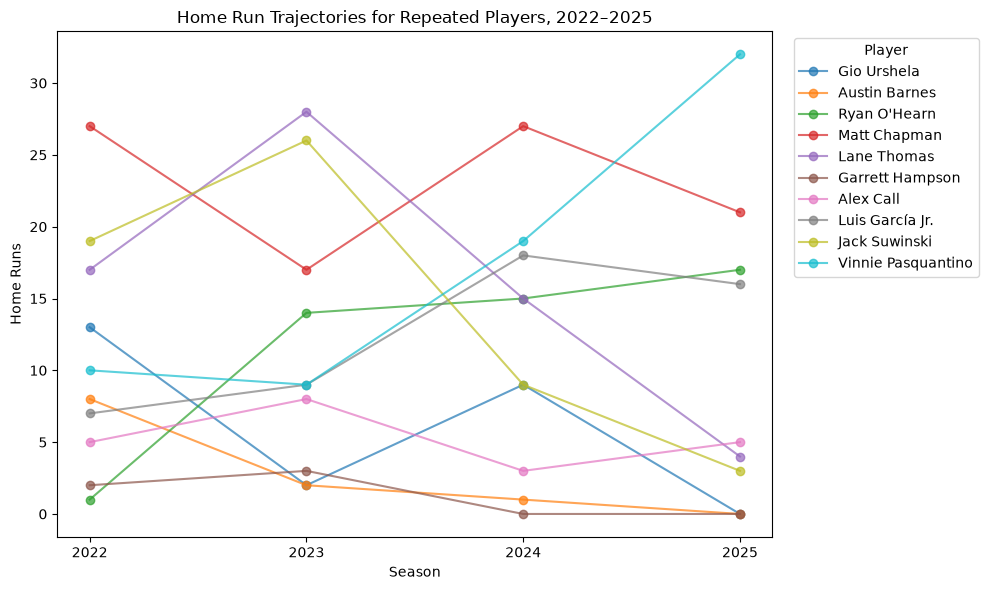

In [20]:
season_count = (
    hitter_data_22to25[hitter_data_22to25["PA"] > 0]
    .groupby("PlayerId")["Season"]
    .nunique()
)

four_year_players = season_count[
    season_count == 4
].index

sample_players = (
    hitter_data_22to25[
        hitter_data_22to25["PlayerId"].isin(four_year_players)
        & (hitter_data_22to25["PA"] > 0)
    ]["PlayerId"]
    .drop_duplicates()
    .sample(10, random_state=42)
)
plot_data = hitter_data_22to25[
    hitter_data_22to25["PlayerId"].isin(sample_players)
    & (hitter_data_22to25["PA"] > 0)
]

plt.figure(figsize=(10, 6))

for player_id, group in plot_data.groupby("PlayerId"):
    group = group.sort_values("Season")
    player_name = group["Name"].dropna().iloc[0] if not group["Name"].dropna().empty else str(player_id)

    plt.plot(
        group["Season"],
        group["HR"],
        marker="o",
        alpha=0.7,
        label=player_name
    )

plt.xlabel("Season")
plt.ylabel("Home Runs")
plt.title("Home Run Trajectories for Repeated Players, 2022–2025")
plt.xticks([2022, 2023, 2024, 2025])
plt.legend(title="Player", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

plt.show()

In [25]:
current = hitter_data_22to25[
    ["PlayerId", "Season", "HR"]
].copy()

next_year = hitter_data_22to25[
    ["PlayerId", "Season", "HR"]
].copy()

next_year["Season"] = next_year["Season"] - 1
next_year = next_year.rename(columns={"HR": "HR_next"})

hr_pairs = current.merge(
    next_year,
    on=["PlayerId", "Season"]
)

print("the correlation between current and next year's home runs is:", hr_pairs["HR"].corr(hr_pairs["HR_next"]))

the correlation between current and next year's home runs is: 0.7955979182428949


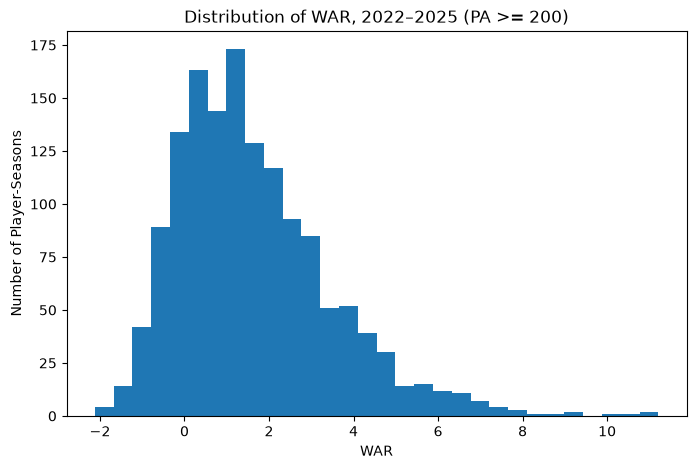

In [30]:
# Distribution of WAR, 2022–2025
plt.figure(figsize=(8, 5))

plt.hist(
    hitter_data_22to25.loc[hitter_data_22to25["PA"] >= 200, "WAR"].dropna(),
    bins=30,
)

plt.xlabel("WAR")
plt.ylabel("Number of Player-Seasons")
plt.title("Distribution of WAR, 2022–2025 (PA >= 200)")

plt.show()

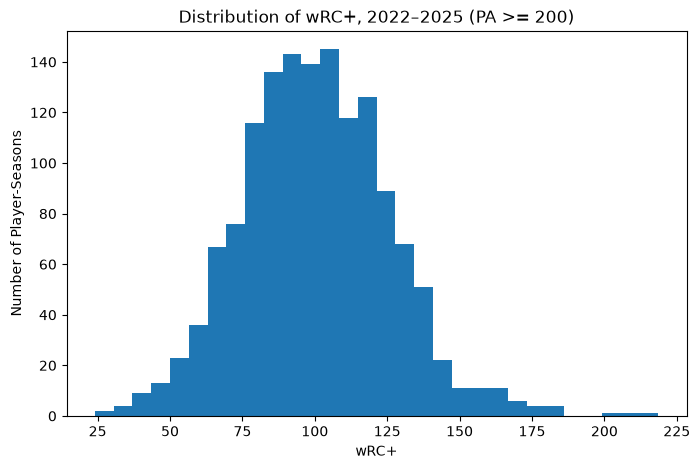

In [31]:

plt.figure(figsize=(8, 5))

plt.hist(
    hitter_data_22to25.loc[hitter_data_22to25["PA"] >= 200, "wRC+"].dropna(),
    bins=30,
)

plt.xlabel("wRC+")
plt.ylabel("Number of Player-Seasons")
plt.title("Distribution of wRC+, 2022–2025 (PA >= 200)")

plt.show()

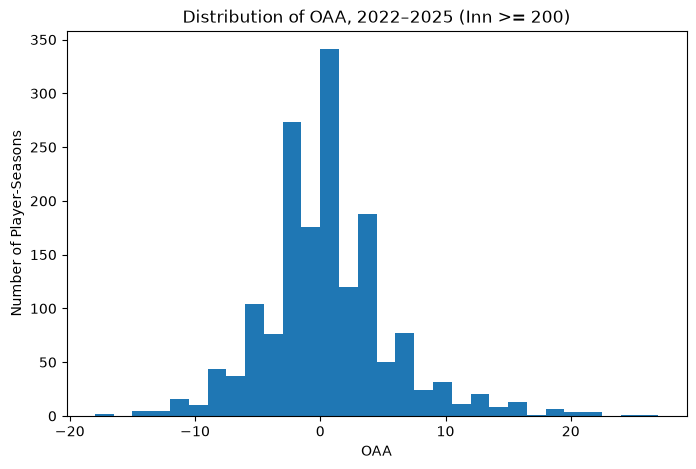

In [32]:
plt.figure(figsize=(8, 5))

plt.hist(
    defensive_22to25.loc[defensive_22to25["Inn"] >= 200, "OAA"].dropna(),
    bins=30,
)

plt.xlabel("OAA")
plt.ylabel("Number of Player-Seasons")
plt.title("Distribution of OAA, 2022–2025 (Inn >= 200)")

plt.show()

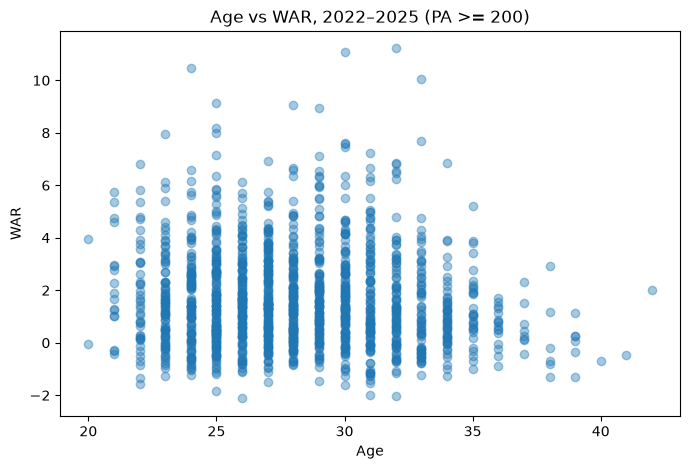

In [ ]:
# filter the hitter data for players with at least 200 plate appearances
hitter_22to25_PA200 = hitter_data_22to25[
    hitter_data_22to25["PA"] >= 200
].copy()

# Age vs WAR, 2022–2025 (PA >= 200)
plt.figure(figsize=(8, 5))

plt.scatter(
    hitter_22to25_PA200["Age"],
    hitter_22to25_PA200["WAR"],
    alpha=0.4
)

plt.xlabel("Age")
plt.ylabel("WAR")
plt.title("Age vs WAR, 2022–2025 (PA >= 200)")

plt.show()

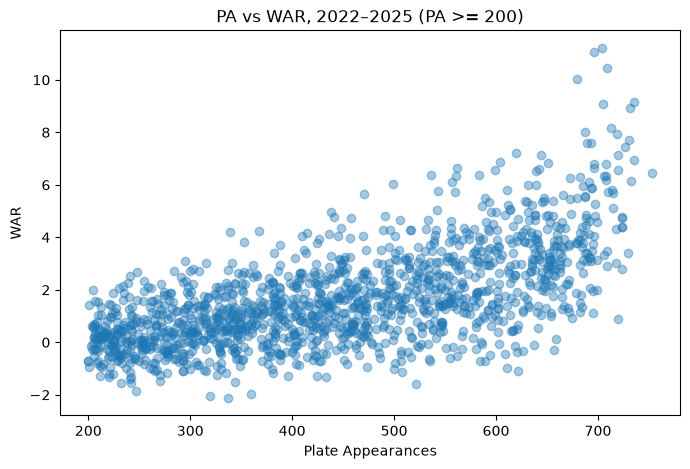

In [ ]:
# PA vs WAR, 2022–2025 (PA >= 200)
plt.figure(figsize=(8, 5))
plt.scatter(
    hitter_22to25_PA200["PA"],
    hitter_22to25_PA200["WAR"],
    alpha=0.4
)

plt.xlabel("Plate Appearances")
plt.ylabel("WAR")
plt.title("PA vs WAR, 2022–2025 (PA >= 200)")

plt.show()